# 01 · Data audit and attrition

**In the story** (notebook 00, §2): this is where the sample comes from. It yields 1.06 million SPX pairs in 2020 and 7.6 million over 2011–2023, with at least 14 days to expiry, an absolute delta of 0.05–0.95 and trading on day one; in 2020, 98.7% of eligible pairs have a usable next-session quote.

**What this notebook establishes.** The data are OptionsDX's end-of-day SPX option quotes. Before any hedging number, it checks four things:
- whether the quotes are fit for a one-day hedging study;
- which option-days enter the analysis (rules E1–E8 of `analysis_plan.md` §5);
- how many are lost because the next session's quote is missing (*attrition*);
- what the sample is made of.

Every number here is data quality only; no hedging error is computed. The processing rules are in `DATA.md`.

**The unit of observation.** A *pair* is one contract on NYSE session *t* (day one), followed to the same contract on the next NYSE session (day two). A hedge set at day one's close is judged by the option's and the index's moves to day two's close. That is Lecture 7's discrete delta-hedging P&L, cut to one period.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
R = ROOT / "results"
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})

## Eligibility and the vendor's volume coding

Ruf and Wang (2022) keep an option-day only if it traded that day (positive volume), since an untraded quote may be stale.

**Our data needed one correction.** Through 2021, OptionsDX never records a volume above 999. On the evidence of day-to-day transitions, it leaves the field *empty* when 1,000 or more contracts trade. It also leaves it empty for contracts that have not traded, and the last-trade price separates the two cases:
- **"empty" with a positive last price** means a heavily traded day;
- **"empty" with a last price of 0** means no trade.

So rule E7 is: positive volume, or empty volume with a positive last price. The table shows how many pairs each clause admits.

In [2]:
e7 = pd.read_csv(R / "attrition/e7_clause.csv")
e7

,year,cp,"empty, last > 0",ineligible,volume > 0
0,2019,C,10023,380822,243832
1,2019,P,15120,289268,312938
2,2020,C,10092,422194,485493
3,2020,P,15246,330412,560187


## Attrition: eligible pairs without a usable next-session quote

A pair needs a two-sided quote (a bid and an ask) for the same contract on the next session.
- **When the vendor lacks the whole session,** the pair is lost (`vendor_missing_session`); it never turns into a two-day hedge.
- **When the bid vanishes** (`one_sided_next`), the value is unknown. The plan stress-tests those pairs with endpoint scenarios (§5).

In the table, the `2020` rows exclude the stress period (2020-02-24 to 04-30), which has its own `stress` rows; together they give 98.7% usable pairs for 2020.

In [3]:
st = pd.read_csv(R / "attrition/by_status.csv")
st["lost_share"] = 1 - st.ok / st[["ok", "one_sided_next", "vendor_missing_session"]].sum(axis=1)
st

,period,cp,ok,one_sided_next,vendor_missing_session,lost_share
0,2019,C,250230,6,3619,0.014280
1,2019,P,323033,1,5024,0.015317
2,2020,C,386467,42,5995,0.015381
3,2020,P,436087,36,6778,0.015385
4,stress,C,102732,349,0,0.003386
5,stress,P,132169,363,0,0.002739


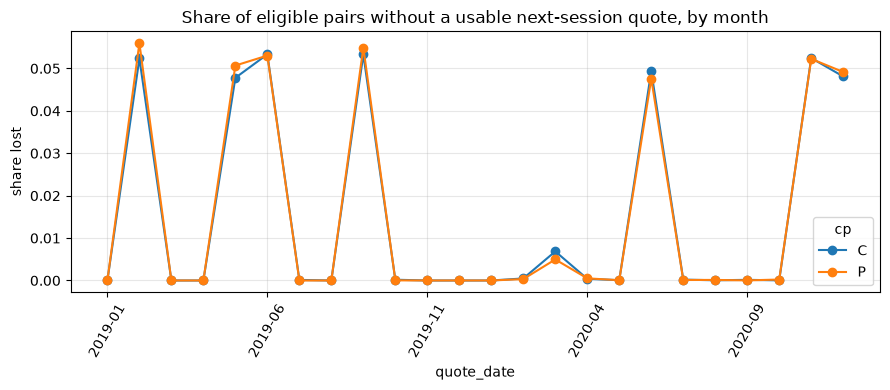

In [4]:
m = pd.read_csv(R / "attrition/by_month.csv")
m["quote_date"] = m.iloc[:, 0].astype(str)
pv = m.pivot(index="quote_date", columns="cp", values="lost_share")
ax = pv.plot(marker="o", title="Share of eligible pairs without a usable next-session quote, by month")
ax.set_ylabel("share lost"); plt.xticks(rotation=60); plt.tight_layout()

**Reading.**
- **Attrition is small and has a known cause.** It comes almost entirely from whole sessions missing at the vendor: ordinary days, and none in the March 2020 crash.
- **Vanished bids** are under 0.1% of pairs, concentrated in the stress period (2020-02-24 to 04-30), mostly far out-of-the-money and long-dated options.
- **Results are therefore stated conditional on a usable day-two quote,** with this table beside them.

## What the sample is made of

Moneyness is measured by the Black–Scholes delta, which puts all maturities on one scale (Lecture 6).
- **The band.** Hull and White's band keeps 0.05 ≤ |δ| ≤ 0.95: both in- and out-of-the-money options.
- **SPX lists far more strikes below the index than above,** and the volatility skew stretches the band further down.
- **So calls are about half in the money, and puts mostly out of the money** (55% and 29% in 2020; 48% and 20% in 2019).

This matters for comparisons with published work: in-the-money calls are a large part of our call sample, and one reason our headline Gains are below Hull and White's (notebook 09).

In [5]:
itm = pd.read_csv(R / "attrition/itm_share.csv"); itm

,year,cp,itm
0,2019,C,0.479019
1,2019,P,0.201079
2,2020,C,0.550193
3,2020,P,0.286353


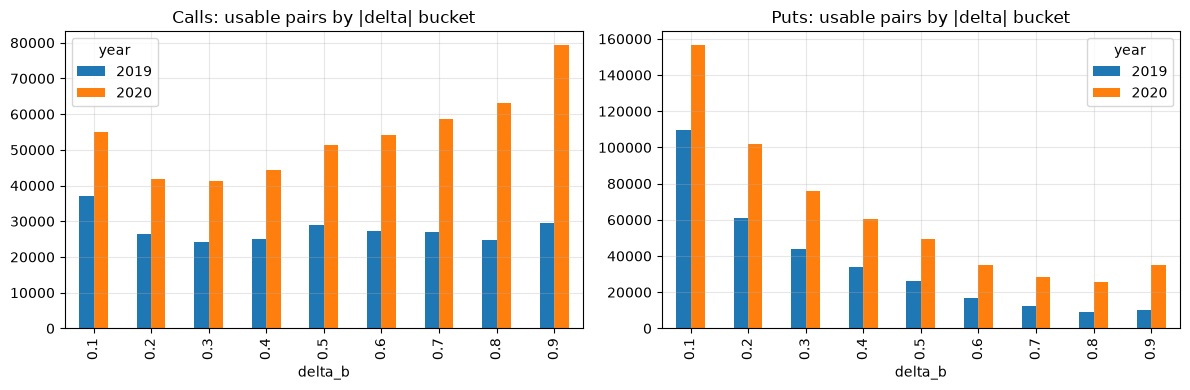

In [6]:
comp = pd.read_csv(R / "attrition/composition.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, cp in zip(axes, ["C", "P"]):
    t = comp[comp.cp == cp].pivot_table(index="delta_b", columns="year", values="pairs", aggfunc="sum")
    t.plot.bar(ax=ax, title=f"{'Calls' if cp == 'C' else 'Puts'}: usable pairs by |delta| bucket")
plt.tight_layout()

## The extra training years (2015–2018)

The 36- and 60-month windows (sensitivities W36 and W60) fit on 2015–2018 as well. A light audit by month found no stamp or settlement anomaly beyond the known ones. The empty-volume share swings by month, from 37% to 77%, but near the money the swing is in untraded new strikes (last price 0), which E7 already excludes.

In [7]:
a = pd.read_csv(R / "audit_light.csv")
a[["month", "sessions", "expiries_per_session", "volume_max", "volume_empty", "empty_last_pos", "iv_converged", "next_ok", "eligible_pairs"]].round(3)

,month,sessions,expiries_per_session,volume_max,volume_empty,empty_last_pos,iv_converged,next_ok,eligible_pairs
0,2015-01,20,26.250,998.0,0.702,0.031,0.885,0.999,18041
1,2015-02,19,27.000,999.0,0.738,0.026,0.888,1.000,14886
2,2015-03,22,27.864,999.0,0.751,0.023,0.844,1.000,17916
3,2015-04,21,28.238,999.0,0.766,0.022,0.831,1.000,16474
4,2015-05,20,27.800,998.0,0.759,0.022,0.843,1.000,16896
5,2015-06,22,28.773,999.0,0.758,0.023,0.837,1.000,19734
6,2015-07,22,29.273,999.0,0.743,0.024,0.838,1.000,21059
7,2015-08,21,30.714,999.0,0.706,0.029,0.826,0.997,25347
8,2015-09,21,29.905,999.0,0.672,0.025,0.854,0.998,30298
9,2015-10,22,27.455,999.0,0.726,0.024,0.833,1.000,22520
